# Can body measurements predict penguin species?

**Author:** ZHU QINYI (MC64890)
**Course:** CISC7204 - Practice 09, Data Science Portfolio

## Research question

Given only the bill length, bill depth, flipper length and body mass of a
penguin, can we identify its species - and which measurement carries the
most information?

This notebook is the narrative companion to `analysis.py`. The script is the
reproducible pipeline; this notebook walks through the reasoning with inline
figures.

## 1. Setup

All random seeds are fixed at `RANDOM_STATE = 42` so the results below can be
reproduced exactly.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import (StratifiedKFold, cross_val_score,
                                     cross_val_predict, train_test_split)
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

RANDOM_STATE = 42
FEATURES = ["bill_length_mm", "bill_depth_mm", "flipper_length_mm", "body_mass_g"]
SPECIES_ORDER = ["Adelie", "Chinstrap", "Gentoo"]
PALETTE = {"Adelie": "#0072B2", "Chinstrap": "#D55E00", "Gentoo": "#009E73"}

sns.set(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110
pd.set_option("display.width", 100)

## 2. Load the data

Raw file: `data/penguins.csv`, 344 individuals. Source and licence are in the
repository `README.md` (Palmer Archipelago penguins, CC0 1.0, collected by
Gorman, Williams & Fraser 2014).

In [2]:
df = pd.read_csv("../data/penguins.csv")
print("shape:", df.shape)
df.head()

shape: (344, 8)


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,year
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,male,2007
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,female,2007
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,female,2007
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN,2007
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,female,2007


### 2.1 Structure and missing values

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 344 entries, 0 to 343
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   species            344 non-null    object 
 1   island             344 non-null    object 
 2   bill_length_mm     342 non-null    float64
 3   bill_depth_mm      342 non-null    float64
 4   flipper_length_mm  342 non-null    float64
 5   body_mass_g        342 non-null    float64
 6   sex                333 non-null    object 
 7   year               344 non-null    int64  
dtypes: float64(4), int64(1), object(3)
memory usage: 21.6+ KB


In [4]:
missing = df.isna().sum()
missing[missing > 0].to_frame("n_missing").assign(
    pct=lambda t: (100 * t["n_missing"] / len(df)).round(1))

,n_missing,pct
bill_length_mm,2,0.6
bill_depth_mm,2,0.6
flipper_length_mm,2,0.6
body_mass_g,2,0.6
sex,11,3.2


Only 2 rows are missing a body measurement, so dropping them costs
essentially nothing. The 11 rows missing `sex` are kept for the species
model (which does not use `sex`) but excluded from any sex comparison.

### 2.2 Clean

In [5]:
df = df.dropna(subset=FEATURES).copy()
df["bill_ratio"] = df["bill_length_mm"] / df["bill_depth_mm"]
print("analysed rows:", len(df))
df[FEATURES].describe().round(1)

analysed rows: 342


,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g
count,342.0,342.0,342.0,342.0
mean,43.9,17.2,200.9,4201.8
std,5.5,2.0,14.1,802.0
min,32.1,13.1,172.0,2700.0
25%,39.2,15.6,190.0,3550.0
50%,44.4,17.3,197.0,4050.0
75%,48.5,18.7,213.0,4750.0
max,59.6,21.5,231.0,6300.0


## 3. Exploratory analysis

### 3.1 Bill length vs bill depth

This single scatter plot is the core of the story: the three species occupy
almost disjoint regions. Gentoo has a long but shallow bill, Adelie a short
deep bill, and Chinstrap a long deep bill.

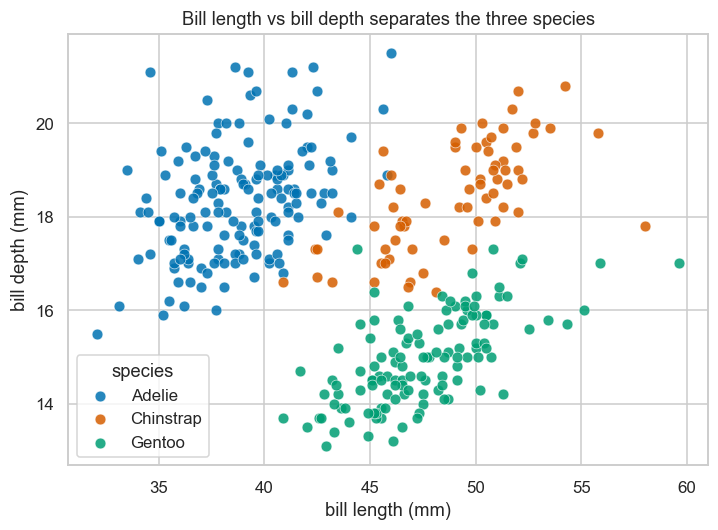

In [6]:
fig, ax = plt.subplots(figsize=(7.5, 5.2))
for sp in SPECIES_ORDER:
    sub = df[df["species"] == sp]
    ax.scatter(sub["bill_length_mm"], sub["bill_depth_mm"], s=50, alpha=0.85,
               color=PALETTE[sp], label=sp, edgecolor="white", linewidth=0.4)
ax.set_xlabel("bill length (mm)")
ax.set_ylabel("bill depth (mm)")
ax.set_title("Bill length vs bill depth separates the three species")
ax.legend(title="species")
plt.show()

### 3.2 Overall size

Gentoo is visibly the largest species on both flipper length and body mass -
roughly 27 mm more flipper and 1.4 kg heavier than Adelie on average.

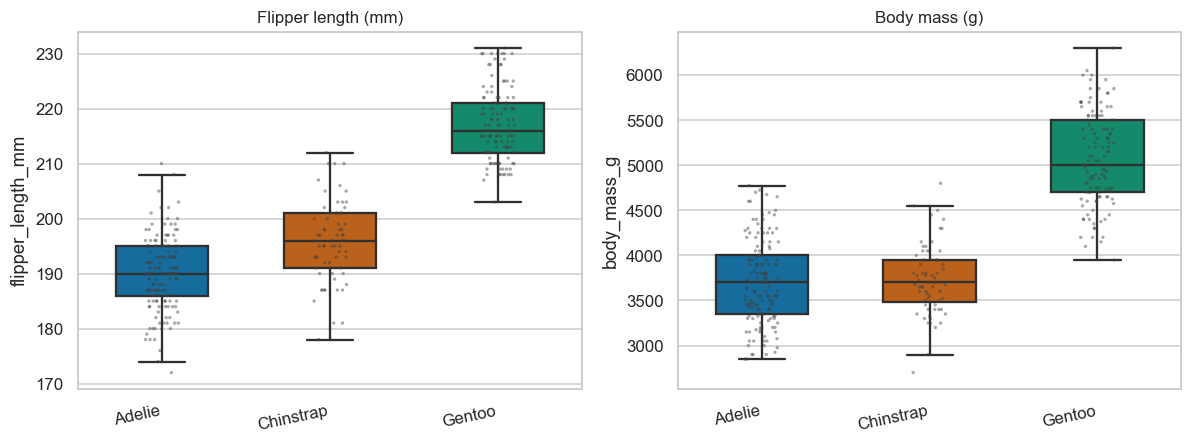

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
for ax, col, title in zip(axes, ["flipper_length_mm", "body_mass_g"],
                          ["Flipper length (mm)", "Body mass (g)"]):
    sns.boxplot(data=df, x="species", y=col, order=SPECIES_ORDER,
                palette=PALETTE, ax=ax, width=0.55, showfliers=False)
    sns.stripplot(data=df, x="species", y=col, order=SPECIES_ORDER,
                  color="0.25", size=2.2, alpha=0.45, ax=ax)
    ax.set_title(title, fontsize=11)
    ax.set_xlabel("")
    plt.setp(ax.get_xticklabels(), rotation=12, ha="right")
plt.tight_layout()
plt.show()

### 3.3 Correlated features

Flipper length and body mass are strongly correlated (r ~ 0.87), so they
carry partly redundant information. That matters for interpreting the
feature-importance ranking later.

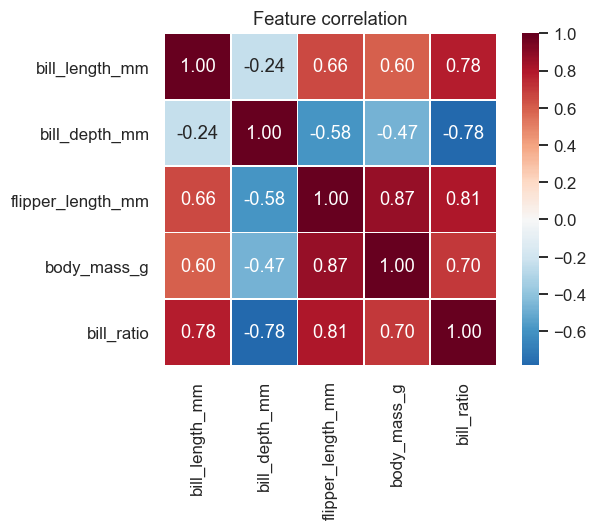

In [8]:
sns.heatmap(df[FEATURES + ["bill_ratio"]].corr(), annot=True, fmt=".2f",
            cmap="RdBu_r", center=0, square=True, linewidths=0.5)
plt.title("Feature correlation")
plt.show()

## 4. Modelling

Two deliberately simple baselines: a scaled logistic regression and a random
forest. Both are evaluated with 5-fold **stratified** cross-validation
(needed because the classes are imbalanced: 152 Adelie vs 68 Chinstrap).

In [9]:
X, y = df[FEATURES], df["species"]
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

models = {
    "Logistic regression": Pipeline([("scale", StandardScaler()),
                                     ("clf", LogisticRegression(max_iter=1000,
                                                                random_state=RANDOM_STATE))]),
    "Random forest": RandomForestClassifier(n_estimators=400, min_samples_leaf=2,
                                            random_state=RANDOM_STATE),
}

rows = []
for name, model in models.items():
    scores = cross_val_score(model, X, y, cv=cv, scoring="accuracy")
    rows.append({"model": name, "cv_accuracy": scores.mean(),
                 "cv_std": scores.std()})
pd.DataFrame(rows).round(3)

,model,cv_accuracy,cv_std
0,Logistic regression,0.988,0.011
1,Random forest,0.977,0.012


### 4.1 Per-class performance

Out-of-fold predictions over all 342 rows:

In [10]:
rf = models["Random forest"]
pred = cross_val_predict(rf, X, y, cv=cv)
print(classification_report(y, pred, labels=SPECIES_ORDER))

              precision    recall  f1-score   support

      Adelie       0.97      0.98      0.98       151
   Chinstrap       0.94      0.94      0.94        68
      Gentoo       1.00      0.99      1.00       123

    accuracy                           0.98       342
   macro avg       0.97      0.97      0.97       342
weighted avg       0.98      0.98      0.98       342



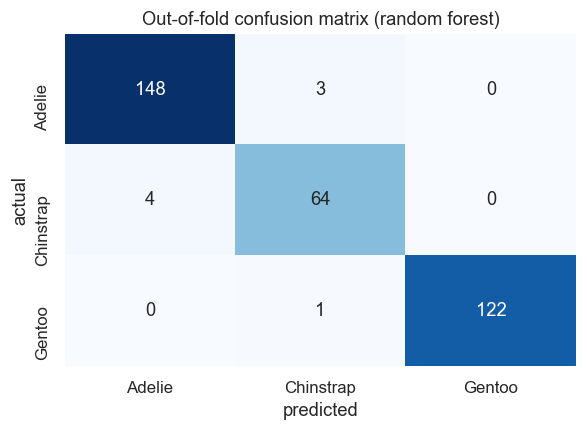

In [11]:
cm = confusion_matrix(y, pred, labels=SPECIES_ORDER)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False,
            xticklabels=SPECIES_ORDER, yticklabels=SPECIES_ORDER)
plt.xlabel("predicted")
plt.ylabel("actual")
plt.title("Out-of-fold confusion matrix (random forest)")
plt.show()

### 4.2 Which measurement matters most?

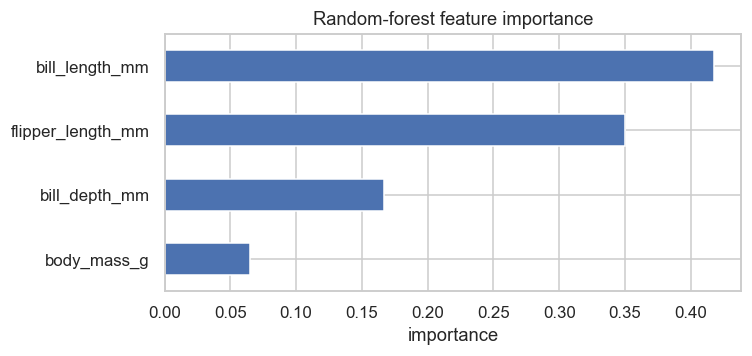

body_mass_g          0.065
bill_depth_mm        0.167
flipper_length_mm    0.350
bill_length_mm       0.418
dtype: float64

In [12]:
rf.fit(X, y)
imp = pd.Series(rf.feature_importances_, index=FEATURES).sort_values()
imp.plot(kind="barh", color="#4C72B0", figsize=(7, 3.4))
plt.xlabel("importance")
plt.title("Random-forest feature importance")
plt.tight_layout()
plt.show()
imp.round(3)

## 5. Findings and limitation

**Findings**

1. Body measurements alone identify species with ~98% cross-validated
   accuracy; bill length is the single most informative feature.
2. The three species separate along two axes: bill shape (length vs depth)
   and overall body size (flipper length, mass).
3. Gentoo is the easiest to identify - it is both larger and uniquely
   shallow-billed.
4. The remaining errors are almost entirely Adelie/Chinstrap confusions.

**Limitation**

This is a 3-class problem on 342 individuals from a single archipelago, and
several features are strongly correlated, so the model is descriptive rather
than causal - it cannot tell us *why* the species differ, and it should not be
expected to generalise to penguins from other regions.

In [13]:
chinstrap = df[df["species"] == "Chinstrap"]
band = chinstrap[(chinstrap["bill_length_mm"] >= 42) &
                 (chinstrap["bill_length_mm"] <= 48)]
print("Chinstrap with bill length in the 42-48 mm Adelie band: %d of %d"
      % (len(band), len(chinstrap)))
print("Rows missing sex (excluded from any sex-based comparison): %d of %d"
      % (df["sex"].isna().sum(), len(df)))

Chinstrap with bill length in the 42-48 mm Adelie band: 26 of 68
Rows missing sex (excluded from any sex-based comparison): 9 of 342
